In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, confusion_matrix , precision_score, recall_score )

# ---------------- CONFIGURATION (change here only) ----------------
DATA_PATH         = "/content/drive/MyDrive/merged_dataset.csv"
SAMPLE_SIZE       = 100_000
RARE_LIMIT        = 5_000
MIN_CLASS_SAMPLES = 50
RANDOM_STATE      = 42
# ------------------------------------------------------------------

sns.set_theme(style="whitegrid")
print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Not in Colab - reading from local path.")

df = pd.read_csv("/content/drive/MyDrive/merged_dataset.csv")
print("Dataset loaded successfully!")
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset loaded successfully!


,No.,Time,Source,Destination,Protocol,Length,Info
0,1,2022-06-28 19:39:34.110362,10.215.173.1,10.215.173.2,TCP,60,49746 > 853 [SYN] Seq=0 Win=65535 Len=0 MSS=...
1,2,2022-06-28 19:39:34.211036,10.215.173.1,10.215.173.2,DNS,78,Standard query 0x0eee A r2---sn-ogueln67.googl...
2,3,2022-06-28 19:39:34.325802,10.215.173.2,10.215.173.1,DNS,378,Standard query response 0x0eee A r2---sn-oguel...
3,4,2022-06-28 19:39:34.328918,10.215.173.1,142.251.90.71,QUIC,1278,"Initial, DCID=017e2a75112a60c8, PKN: 1, PING, ..."
4,5,2022-06-28 19:39:34.332994,10.215.173.1,142.251.90.71,TCP,60,52866 > 443 [SYN] Seq=0 Win=65535 Len=0 MSS=...


In [5]:
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nData types:")
print(df.dtypes)
print()
df.info()

Shape: (6263188, 7)

Columns: ['No.', 'Time', 'Source', 'Destination', 'Protocol', 'Length', 'Info']

Data types:
No.             int64
Time           object
Source         object
Destination    object
Protocol       object
Length          int64
Info           object
dtype: object

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6263188 entries, 0 to 6263187
Data columns (total 7 columns):
 #   Column       Dtype 
---  ------       ----- 
 0   No.          int64 
 1   Time         object
 2   Source       object
 3   Destination  object
 4   Protocol     object
 5   Length       int64 
 6   Info         object
dtypes: int64(2), object(5)
memory usage: 334.5+ MB


In [6]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
No.,6263188.0,NaN,NaN,NaN,986063.895682,864016.201066,1.0,323108.75,669570.0,1482513.25,3145191.0
Time,6263188,6263188,2022-06-28 19:39:34.110362,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Source,6263188,112,211.114.67.81,2819502,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Destination,6263188,113,10.215.173.1,5712397,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Protocol,6263188,14,GQUIC,4395234,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Length,6263188.0,NaN,NaN,NaN,1080.477883,414.06086,40.0,1278.0,1278.0,1278.0,10000.0
Info,6262725,97467,Protected Payload (KP0),222026,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
print("Missing values (full dataset):")
print(df.isnull().sum())

before = len(df)
df = df.dropna(subset=["Protocol", "Time", "Length"])
df["Protocol"] = df["Protocol"].astype(str).str.strip()
df["Length"] = pd.to_numeric(df["Length"], errors="coerce")
df = df.dropna(subset=["Length"])
print(f"\nRows removed: {before - len(df)}  |  Shape now: {df.shape}")

Missing values (full dataset):
No.              0
Time             0
Source           0
Destination      0
Protocol         0
Length           0
Info           463
dtype: int64

Rows removed: 0  |  Shape now: (6263188, 7)


In [8]:
full_counts = df["Protocol"].value_counts()
print("Protocols in FULL data:")
print(full_counts)

rare_protocols = full_counts[full_counts <= RARE_LIMIT].index
rare_df   = df[df["Protocol"].isin(rare_protocols)]
common_df = df[~df["Protocol"].isin(rare_protocols)]

budget = max(SAMPLE_SIZE - len(rare_df), 0)
frac   = min(budget / len(common_df), 1.0)
common_sample = common_df.groupby("Protocol", group_keys=False).sample(
    frac=frac, random_state=RANDOM_STATE)

df = (pd.concat([rare_df, common_sample])
        .sample(frac=1, random_state=RANDOM_STATE)
        .reset_index(drop=True))

del common_df, rare_df, common_sample
print("\nSampled dataset shape:", df.shape)

Protocols in FULL data:
Protocol
GQUIC       4395234
UDP         1552972
QUIC         309325
TCP            2499
TLSv1.3        1930
DNS             520
R-GOOSE         303
DCP-PFT         165
DCP-AF          163
THRIFT           38
TLSv1            22
MPEG TS           9
CLTP              7
ar_drone          1
Name: count, dtype: int64

Sampled dataset shape: (100001, 7)


In [9]:
dup_cols = ["Source", "Destination", "Protocol", "Length", "Info"]
dup_count = df.duplicated(subset=dup_cols).sum()
print("Packets that look identical (ignoring No. and Time):", dup_count)

Packets that look identical (ignoring No. and Time): 38945


Protocol
GQUIC       66266
UDP         23414
QUIC         4664
TCP          2499
TLSv1.3      1930
DNS           520
R-GOOSE       303
DCP-PFT       165
DCP-AF        163
THRIFT         38
TLSv1          22
MPEG TS         9
CLTP            7
ar_drone        1
Name: count, dtype: int64

Number of protocol classes: 14


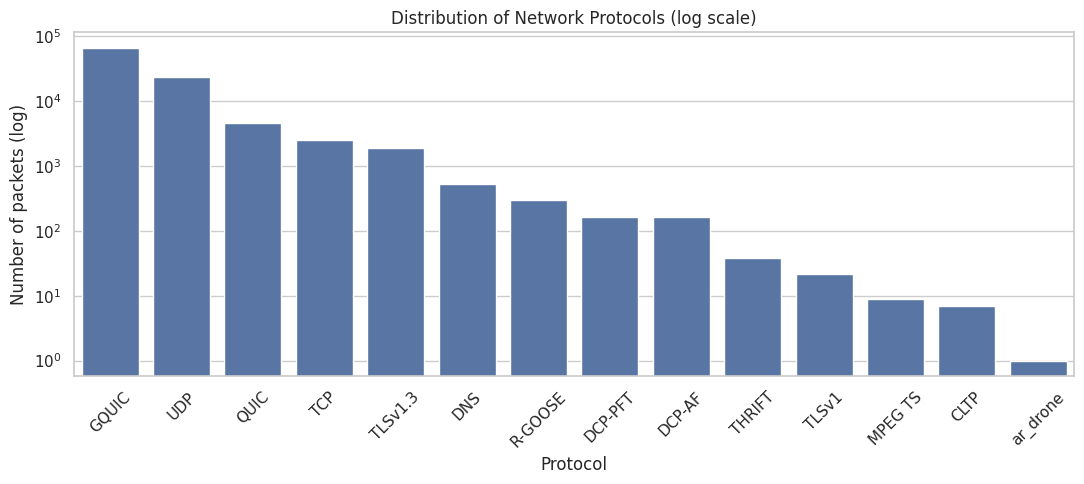

In [10]:
protocol_counts = df["Protocol"].value_counts()
print(protocol_counts)
print("\nNumber of protocol classes:", df["Protocol"].nunique())

plt.figure(figsize=(11, 5))
sns.countplot(data=df, x="Protocol", order=protocol_counts.index)
plt.yscale("log")
plt.xticks(rotation=45)
plt.title("Distribution of Network Protocols (log scale)")
plt.xlabel("Protocol"); plt.ylabel("Number of packets (log)")
plt.tight_layout(); plt.show()

count    100001.000000
mean       1054.205078
std         493.331636
min          40.000000
25%        1270.000000
50%        1278.000000
75%        1278.000000
max       10000.000000
Name: Length, dtype: float64


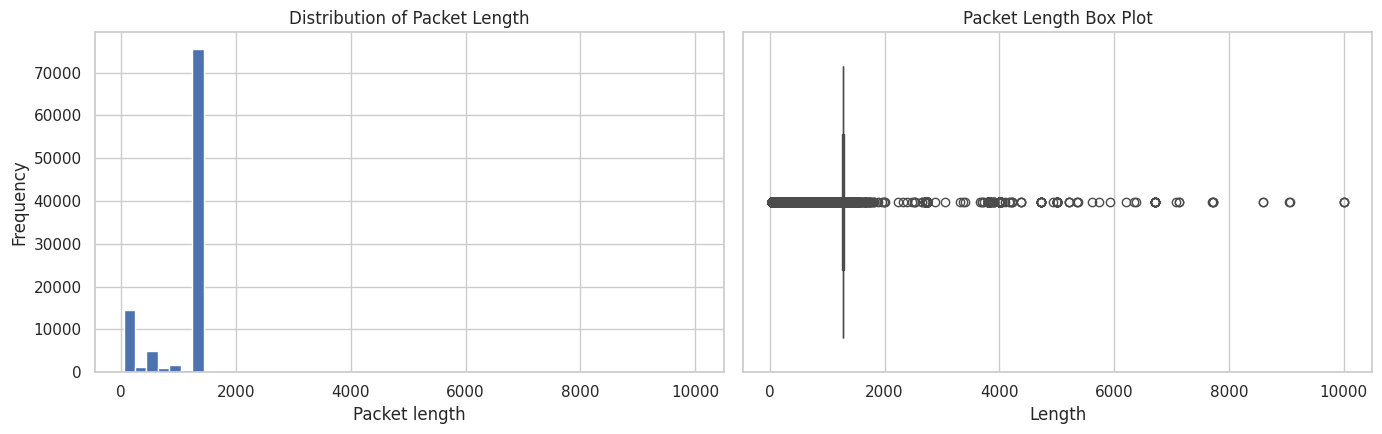

In [11]:
print(df["Length"].describe())

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].hist(df["Length"], bins=50)
ax[0].set_title("Distribution of Packet Length"); ax[0].set_xlabel("Packet length"); ax[0].set_ylabel("Frequency")
sns.boxplot(x=df["Length"], ax=ax[1])
ax[1].set_title("Packet Length Box Plot")
plt.tight_layout(); plt.show()

In [12]:
df["Time"]   = pd.to_datetime(df["Time"], errors="coerce")
df = df.dropna(subset=["Time"]).reset_index(drop=True)

df["Date"]   = df["Time"].dt.date
df["Hour"]   = df["Time"].dt.hour
df["Minute"] = df["Time"].dt.minute
df["Second"] = df["Time"].dt.second

df[["Time", "Date", "Hour", "Minute", "Second"]].head()

,Time,Date,Hour,Minute,Second
0,2022-05-30 10:31:15.417700,2022-05-30,10,31,15
1,2022-05-31 10:38:05.292304,2022-05-31,10,38,5
2,2022-06-28 19:45:30.240277,2022-06-28,19,45,30
3,2022-05-30 08:28:51.079887,2022-05-30,8,28,51
4,2022-05-31 08:03:00.287250,2022-05-31,8,3,0


Packets per capture date and protocol:


Protocol,CLTP,DCP-AF,DCP-PFT,DNS,GQUIC,MPEG TS,QUIC,R-GOOSE,TCP,THRIFT,TLSv1,TLSv1.3,UDP,ar_drone
Date,,,,,,,,,,,,,,
2022-05-30,0,0,0,0,23492,0,0,0,0,0,0,0,0,0
2022-05-31,0,0,0,0,42774,0,0,0,0,0,0,0,0,0
2022-06-28,7,163,165,520,0,9,4664,303,2499,38,22,1930,23414,1


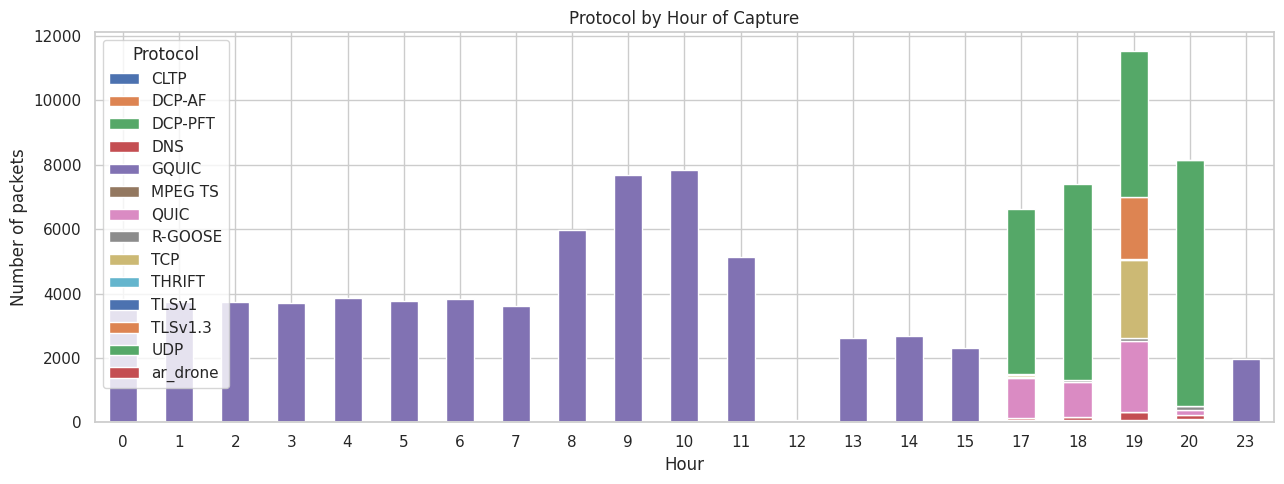

In [13]:
print("Packets per capture date and protocol:")
display(pd.crosstab(df["Date"], df["Protocol"]))

hour_ct = pd.crosstab(df["Hour"], df["Protocol"])
hour_ct.plot(kind="bar", stacked=True, figsize=(13, 5))
plt.title("Protocol by Hour of Capture")
plt.xlabel("Hour"); plt.ylabel("Number of packets")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

In [14]:
info = df["Info"].fillna("").astype(str)

df["Info_Type"] = np.select(
    [info.str.contains("Payload (Encrypted)", regex=False),
     info.str.contains(r"\d+\s*>\s*\d+", regex=True)],
    ["Encrypted payload", "Port information"],
    default="Other")

display(pd.crosstab(df["Protocol"], df["Info_Type"], normalize="index").round(3))

Info_Type,Encrypted payload,Other,Port information
Protocol,,,
CLTP,0.0,1.000,0.000
DCP-AF,0.0,1.000,0.000
DCP-PFT,0.0,1.000,0.000
DNS,0.0,1.000,0.000
GQUIC,1.0,0.000,0.000
MPEG TS,0.0,0.667,0.333
QUIC,0.0,1.000,0.000
R-GOOSE,0.0,1.000,0.000
TCP,0.0,0.000,1.000


In [15]:
info_len = pd.to_numeric(info.str.extract(r"Len=(\d+)", expand=False), errors="coerce")
diff = (df["Length"] - info_len).dropna()
print("Rows that contain Len= in Info:", len(diff))
print("\nDifference (Length - Info Len):")
print(diff.value_counts().head())

Rows that contain Len= in Info: 25916

Difference (Length - Info Len):
28.0    23417
40.0     2181
60.0      192
48.0      125
64.0        1
Name: count, dtype: int64


In [16]:
counts = df["Protocol"].value_counts()
removed = counts[counts < MIN_CLASS_SAMPLES]
print("Removed (too few samples):")
print(removed if len(removed) else "None")

df = df[df["Protocol"].isin(counts[counts >= MIN_CLASS_SAMPLES].index)].reset_index(drop=True)
print("\nFinal dataset shape:", df.shape)
print(df["Protocol"].value_counts())

Removed (too few samples):
Protocol
THRIFT      38
TLSv1       22
MPEG TS      9
CLTP         7
ar_drone     1
Name: count, dtype: int64

Final dataset shape: (99924, 12)
Protocol
GQUIC      66266
UDP        23414
QUIC        4664
TCP         2499
TLSv1.3     1930
DNS          520
R-GOOSE      303
DCP-PFT      165
DCP-AF       163
Name: count, dtype: int64


In [17]:
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(df["Protocol"])
class_names = list(label_encoder.classes_)
labels_all  = list(range(len(class_names)))

print("Classes:", class_names)
print("Encoded sample:", y_encoded[:20])

Classes: ['DCP-AF', 'DCP-PFT', 'DNS', 'GQUIC', 'QUIC', 'R-GOOSE', 'TCP', 'TLSv1.3', 'UDP']
Encoded sample: [3 3 7 3 3 3 3 3 8 3 3 3 3 7 3 3 6 8 3 3]


In [18]:
train_idx, test_idx = train_test_split(
    np.arange(len(df)), test_size=0.20,
    random_state=RANDOM_STATE, stratify=y_encoded)

y_train, y_test = y_encoded[train_idx], y_encoded[test_idx]
print("Training samples:", len(train_idx))
print("Testing samples :", len(test_idx))

Training samples: 79939
Testing samples : 19985


In [19]:
FEATURE_SETS = {
    "Length only (leak-free)":       ["Length"],
    "Length + Time (time shortcut)": ["Length", "Hour", "Minute", "Second"],
}

In [20]:
def build_models():
    return {
        "Logistic Regression": make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=1000, class_weight="balanced")),
        "KNN": make_pipeline(
            StandardScaler(),
            KNeighborsClassifier(n_neighbors=5, n_jobs=-1)),
        "Decision Tree": DecisionTreeClassifier(
            max_depth=10, class_weight="balanced", random_state=RANDOM_STATE),
        "Random Forest": RandomForestClassifier(
            n_estimators=100, class_weight="balanced",
            random_state=RANDOM_STATE, n_jobs=-1),
    }

experiments = {}
rows = []

for set_name, feats in FEATURE_SETS.items():
    X_train = df.loc[train_idx, feats]
    X_test  = df.loc[test_idx,  feats]
    experiments[set_name] = {}

    for model_name, model in build_models().items():
        model.fit(X_train, y_train)
        pred = model.predict(X_test)
        experiments[set_name][model_name] = {"model": model, "pred": pred}

        rows.append({
            "Feature set": set_name,
            "Model": model_name,
            "Accuracy (%)":          accuracy_score(y_test, pred) * 100,
            "Balanced Accuracy (%)": balanced_accuracy_score(y_test, pred) * 100,
            "Macro F1 (%)":          f1_score(y_test, pred, average="macro", zero_division=0) * 100,
        })
    print("Finished:", set_name)

results = pd.DataFrame(rows)
display(results.round(2))

Finished: Length only (leak-free)
Finished: Length + Time (time shortcut)


,Feature set,Model,Accuracy (%),Balanced Accuracy (%),Macro F1 (%)
0,Length only (leak-free),Logistic Regression,62.28,26.41,16.19
1,Length only (leak-free),KNN,79.35,42.58,45.16
2,Length only (leak-free),Decision Tree,70.88,47.57,36.13
3,Length only (leak-free),Random Forest,74.58,47.89,39.89
4,Length + Time (time shortcut),Logistic Regression,67.98,33.25,21.36
5,Length + Time (time shortcut),KNN,96.51,53.20,53.63
6,Length + Time (time shortcut),Decision Tree,77.25,60.47,47.16
7,Length + Time (time shortcut),Random Forest,95.93,61.95,61.92


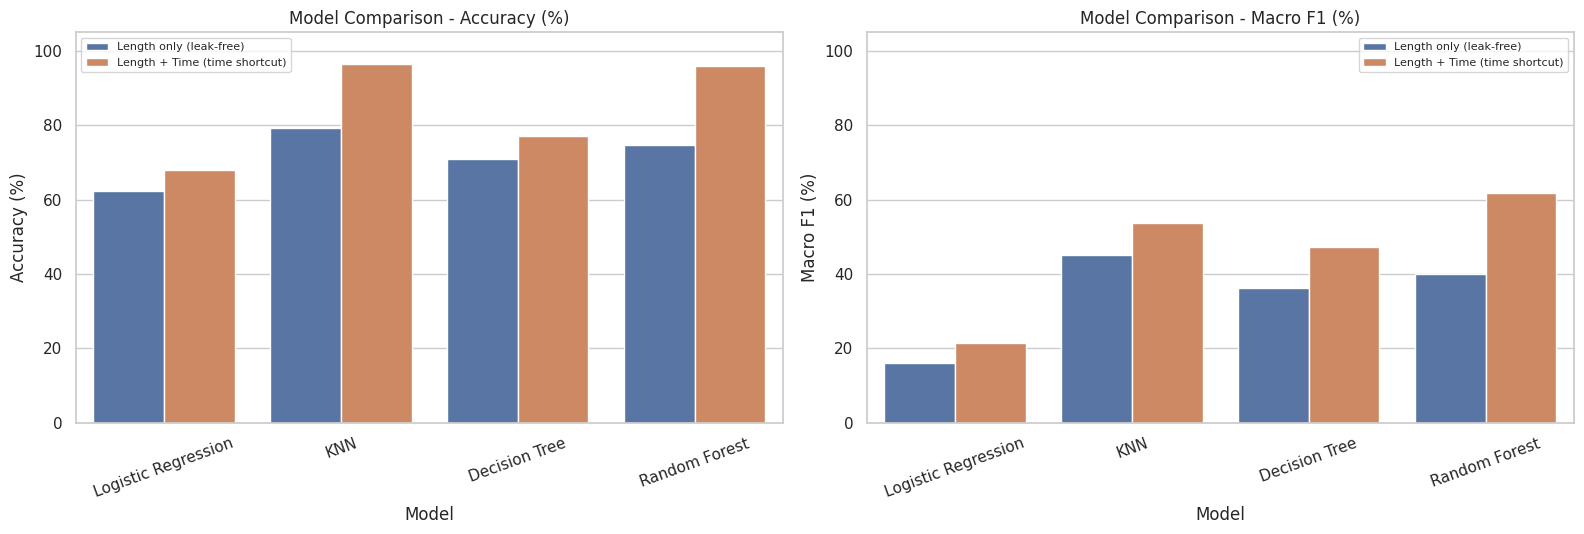

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, metric in zip(axes, ["Accuracy (%)", "Macro F1 (%)"]):
    sns.barplot(data=results, x="Model", y=metric, hue="Feature set", ax=ax)
    ax.set_ylim(0, 105)
    ax.set_title(f"Model Comparison - {metric}")
    ax.tick_params(axis="x", rotation=20)
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [22]:
clean_set = "Length only (leak-free)"
time_set  = "Length + Time (time shortcut)"

for model_name, res in experiments[clean_set].items():
    print("=" * 60)
    print(model_name, "-", clean_set)
    print("=" * 60)
    print(classification_report(y_test, res["pred"], labels=labels_all,
                                target_names=class_names, zero_division=0))

Logistic Regression - Length only (leak-free)
              precision    recall  f1-score   support

      DCP-AF       0.00      0.00      0.00        32
     DCP-PFT       0.00      0.00      0.00        33
         DNS       0.15      0.44      0.23       104
       GQUIC       0.77      0.89      0.82     13253
        QUIC       0.09      0.11      0.10       933
     R-GOOSE       0.00      0.00      0.00        61
         TCP       0.17      0.92      0.28       500
     TLSv1.3       0.17      0.00      0.01       386
         UDP       0.22      0.01      0.02      4683

    accuracy                           0.62     19985
   macro avg       0.17      0.26      0.16     19985
weighted avg       0.57      0.62      0.56     19985

KNN - Length only (leak-free)
              precision    recall  f1-score   support

      DCP-AF       0.00      0.00      0.00        32
     DCP-PFT       0.00      0.00      0.00        33
         DNS       0.83      0.57      0.67       104
  

In [23]:
print("=" * 60)
print("Random Forest -", time_set)
print("=" * 60)
print(classification_report(y_test, experiments[time_set]["Random Forest"]["pred"],
                            labels=labels_all, target_names=class_names, zero_division=0))

Random Forest - Length + Time (time shortcut)
              precision    recall  f1-score   support

      DCP-AF       0.01      0.03      0.02        32
     DCP-PFT       0.02      0.06      0.03        33
         DNS       0.79      0.74      0.76       104
       GQUIC       1.00      1.00      1.00     13253
        QUIC       0.92      0.87      0.89       933
     R-GOOSE       0.01      0.05      0.02        61
         TCP       0.98      0.99      0.99       500
     TLSv1.3       0.96      0.95      0.95       386
         UDP       0.94      0.89      0.92      4683

    accuracy                           0.96     19985
   macro avg       0.63      0.62      0.62     19985
weighted avg       0.97      0.96      0.97     19985



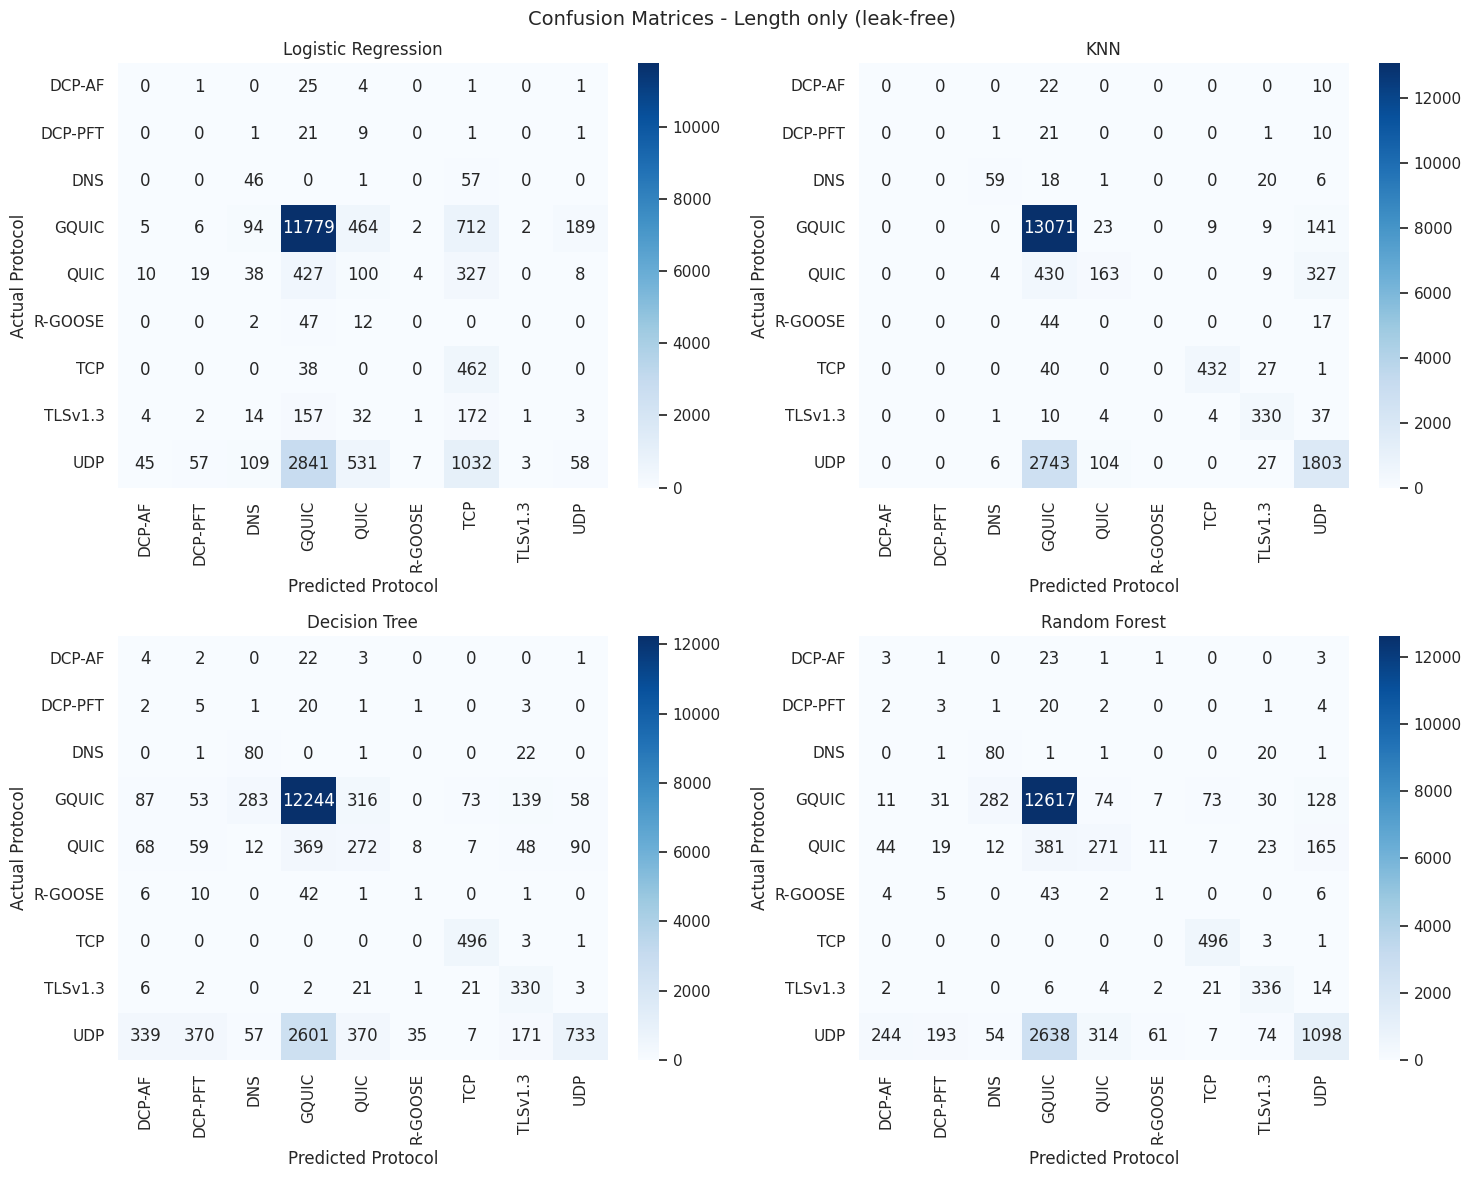

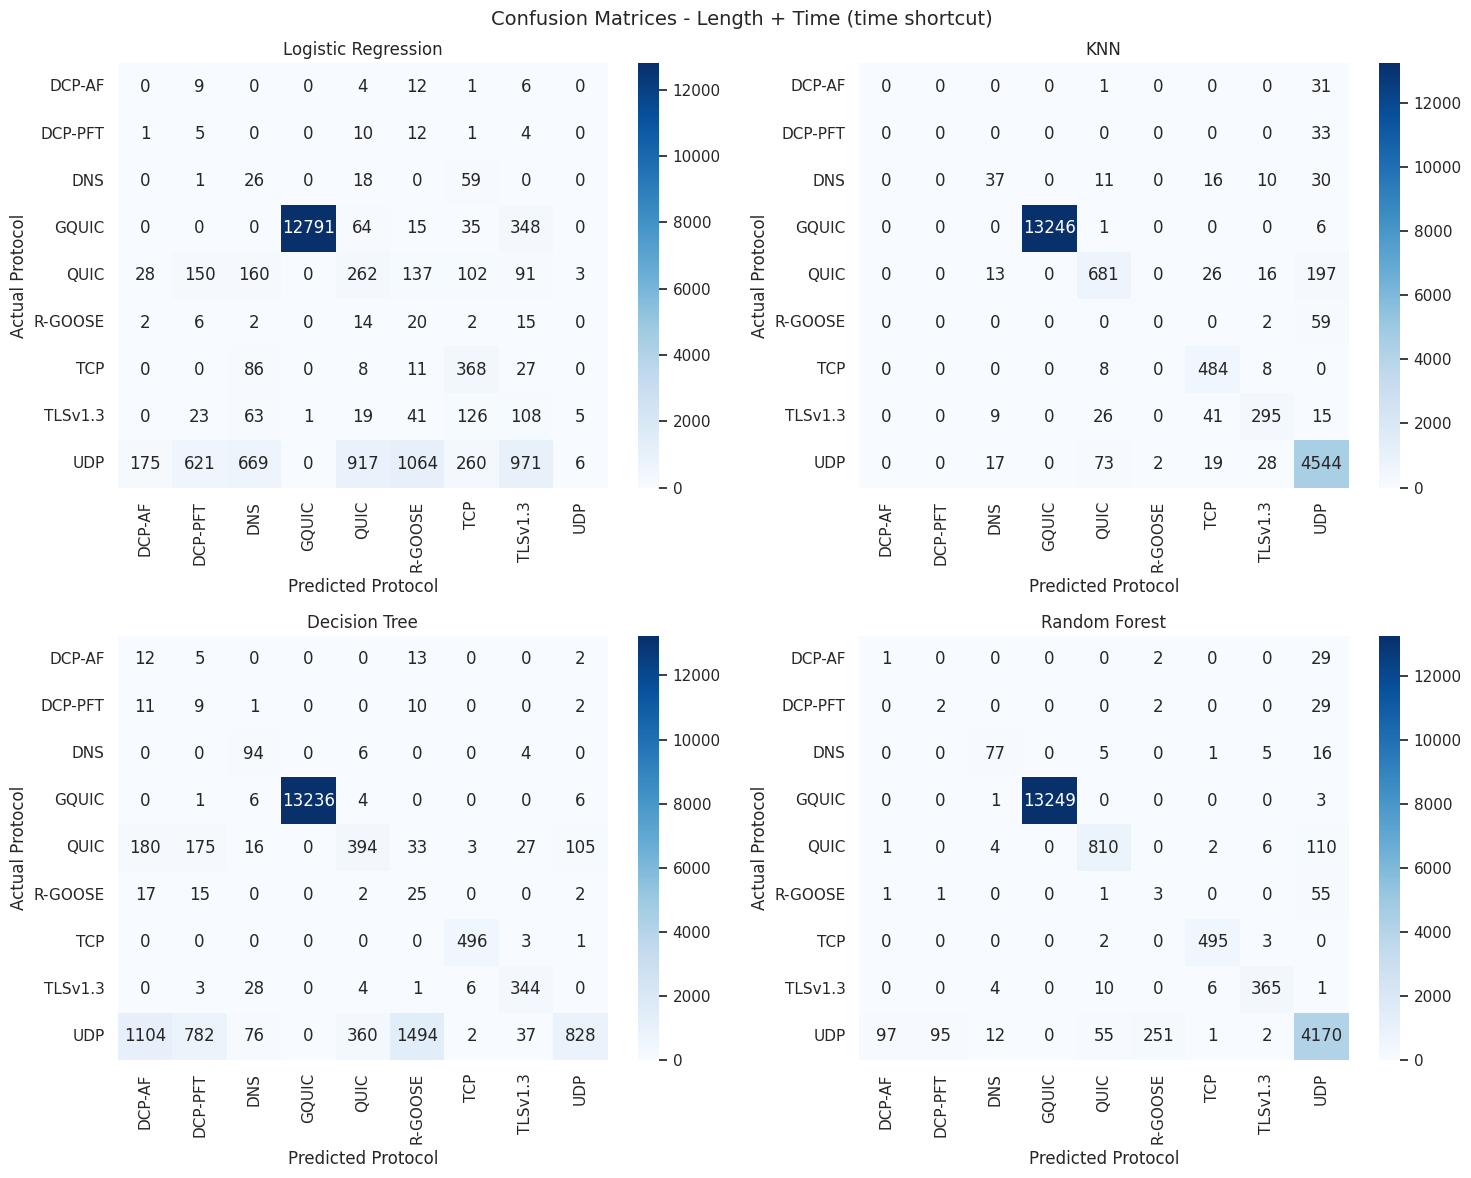

In [24]:
def plot_cm_grid(set_name):
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))
    for ax, (model_name, res) in zip(axes.flatten(), experiments[set_name].items()):
        cm = confusion_matrix(y_test, res["pred"], labels=labels_all)
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                    xticklabels=class_names, yticklabels=class_names)
        ax.set_title(model_name)
        ax.set_xlabel("Predicted Protocol"); ax.set_ylabel("Actual Protocol")
    fig.suptitle(f"Confusion Matrices - {set_name}", fontsize=14)
    plt.tight_layout(); plt.show()

plot_cm_grid(clean_set)
plot_cm_grid(time_set)

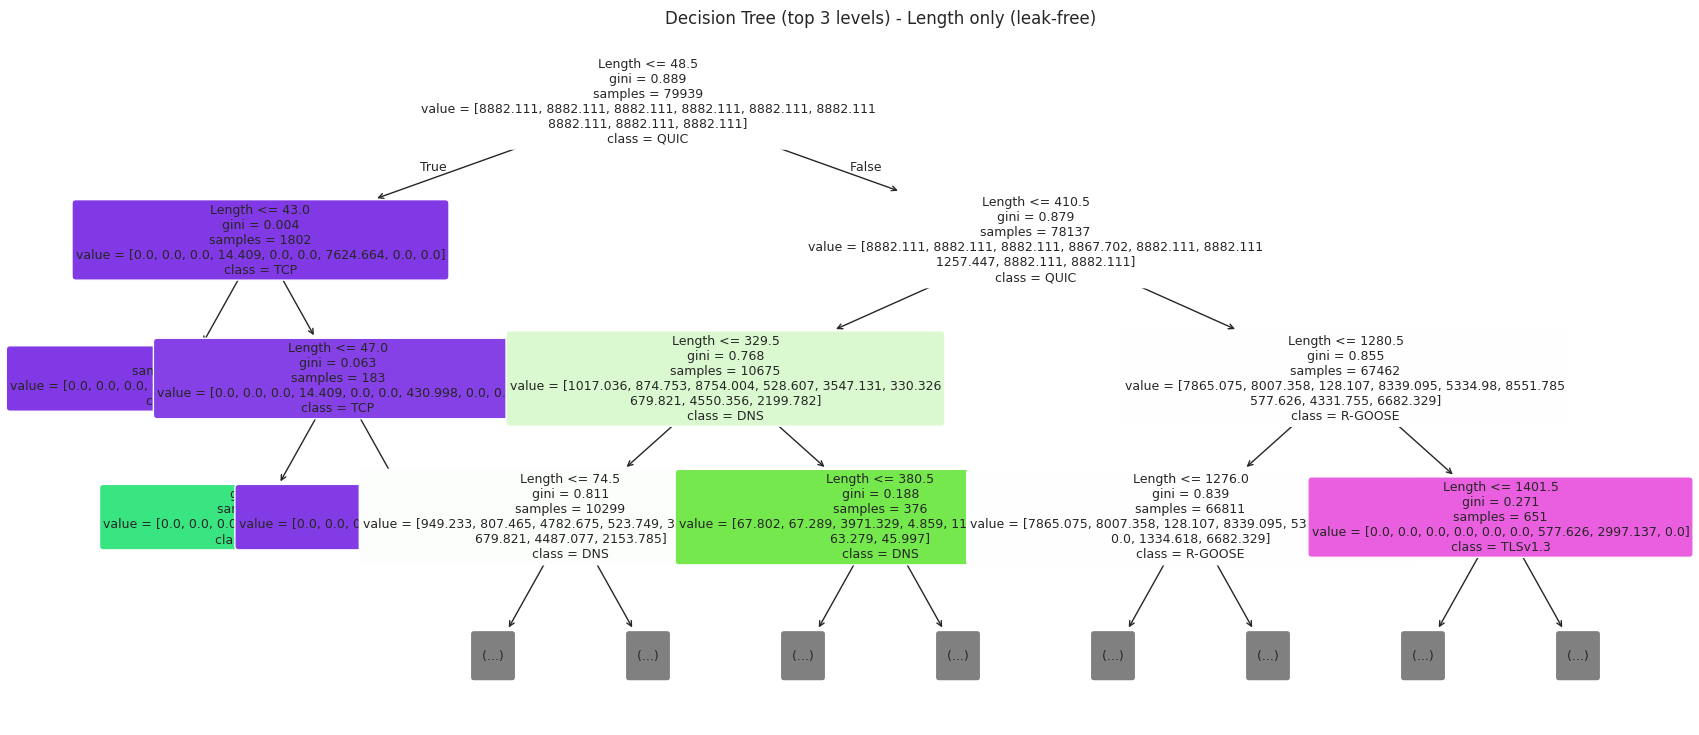

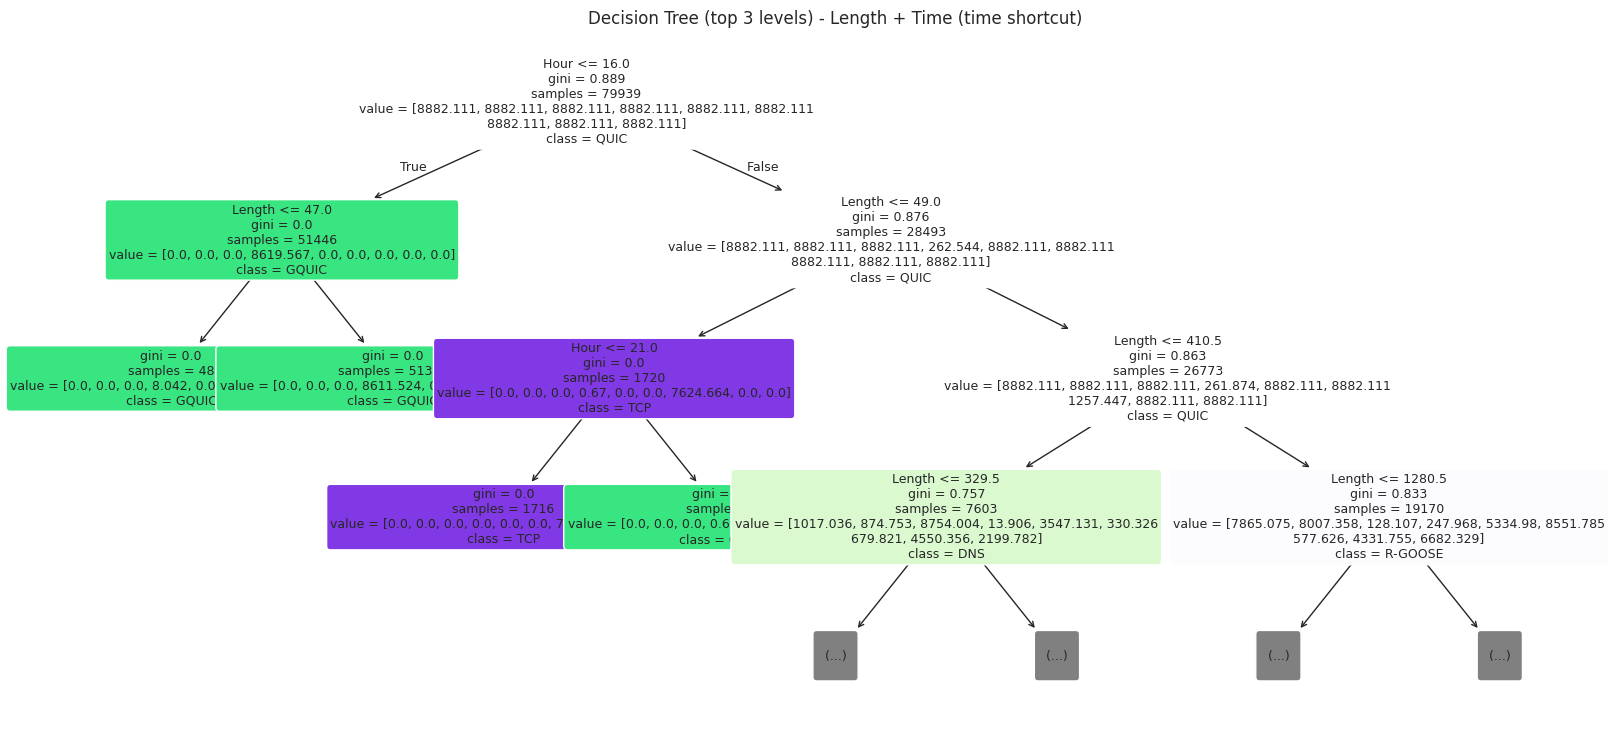

In [25]:
for set_name, feats in FEATURE_SETS.items():
    plt.figure(figsize=(20, 9))
    plot_tree(experiments[set_name]["Decision Tree"]["model"],
              feature_names=feats, class_names=class_names,
              filled=True, rounded=True, max_depth=3, fontsize=9)
    plt.title(f"Decision Tree (top 3 levels) - {set_name}")
    plt.show()

,Feature,Importance
0,Length,0.364487
2,Minute,0.237430
1,Hour,0.214781
3,Second,0.183303


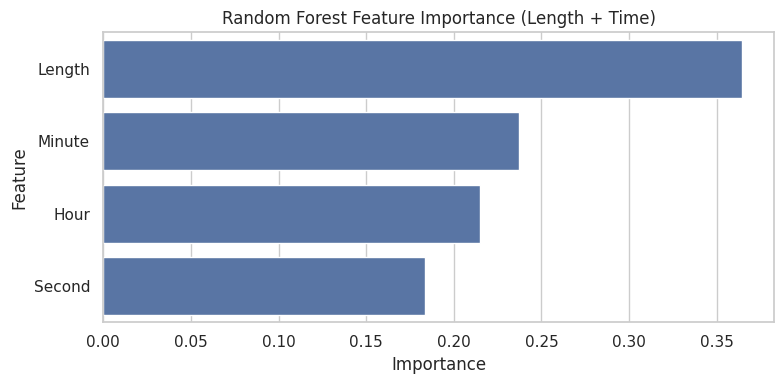

In [26]:
rf_time = experiments[time_set]["Random Forest"]["model"]

feature_importance = (pd.DataFrame({
        "Feature": FEATURE_SETS[time_set],
        "Importance": rf_time.feature_importances_})
    .sort_values("Importance", ascending=False))

display(feature_importance)

plt.figure(figsize=(8, 4))
sns.barplot(data=feature_importance, x="Importance", y="Feature")
plt.title("Random Forest Feature Importance (Length + Time)")
plt.tight_layout(); plt.show()

In [27]:
df_sorted = df.sort_values("Time").reset_index(drop=True)
split = int(len(df_sorted) * 0.80)
train_t, test_t = df_sorted.iloc[:split], df_sorted.iloc[split:]

print("Train period:", train_t["Time"].min(), "->", train_t["Time"].max())
print("Test period :", test_t["Time"].min(),  "->", test_t["Time"].max())

dist = pd.DataFrame({
    "Train": train_t["Protocol"].value_counts(),
    "Test":  test_t["Protocol"].value_counts()}).fillna(0).astype(int)
print("\nProtocol distribution:")
display(dist)

Train period: 2022-05-30 08:25:23.176069 -> 2022-06-28 18:56:53.190427
Test period : 2022-06-28 18:56:53.450940 -> 2022-06-28 20:59:20.089199

Protocol distribution:


,Train,Test
Protocol,,
DCP-AF,68,95
DCP-PFT,70,95
DNS,156,364
GQUIC,66266,0
QUIC,2127,2537
R-GOOSE,97,206
TCP,47,2452
TLSv1.3,24,1906
UDP,11084,12330


In [28]:
yt_train = label_encoder.transform(train_t["Protocol"])
yt_test  = label_encoder.transform(test_t["Protocol"])
chrono_rows = []

for set_name, feats in FEATURE_SETS.items():
    m = RandomForestClassifier(n_estimators=100, class_weight="balanced",
                               random_state=RANDOM_STATE, n_jobs=-1)
    m.fit(train_t[feats], yt_train)
    pred = m.predict(test_t[feats])

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        bal = balanced_accuracy_score(yt_test, pred) * 100

    chrono_rows.append({"Feature set": set_name,
                        "Accuracy (%)": accuracy_score(yt_test, pred) * 100,
                        "Balanced Accuracy (%)": bal})

display(pd.DataFrame(chrono_rows).round(2))

,Feature set,Accuracy (%),Balanced Accuracy (%)
0,Length only (leak-free),24.09,33.71
1,Length + Time (time shortcut),59.73,19.21


,Feature set,Model,Accuracy (%),Balanced Accuracy (%),Macro F1 (%)
1,Length only (leak-free),KNN,79.35,42.58,45.16
3,Length only (leak-free),Random Forest,74.58,47.89,39.89
2,Length only (leak-free),Decision Tree,70.88,47.57,36.13
0,Length only (leak-free),Logistic Regression,62.28,26.41,16.19


FINAL MODEL: KNN
Accuracy          : 79.35%
Balanced Accuracy : 42.58%
Macro F1          : 45.16%

              precision    recall  f1-score   support

      DCP-AF       0.00      0.00      0.00        32
     DCP-PFT       0.00      0.00      0.00        33
         DNS       0.83      0.57      0.67       104
       GQUIC       0.80      0.99      0.88     13253
        QUIC       0.55      0.17      0.27       933
     R-GOOSE       0.00      0.00      0.00        61
         TCP       0.97      0.86      0.91       500
     TLSv1.3       0.78      0.85      0.82       386
         UDP       0.77      0.39      0.51      4683

    accuracy                           0.79     19985
   macro avg       0.52      0.43      0.45     19985
weighted avg       0.78      0.79      0.76     19985



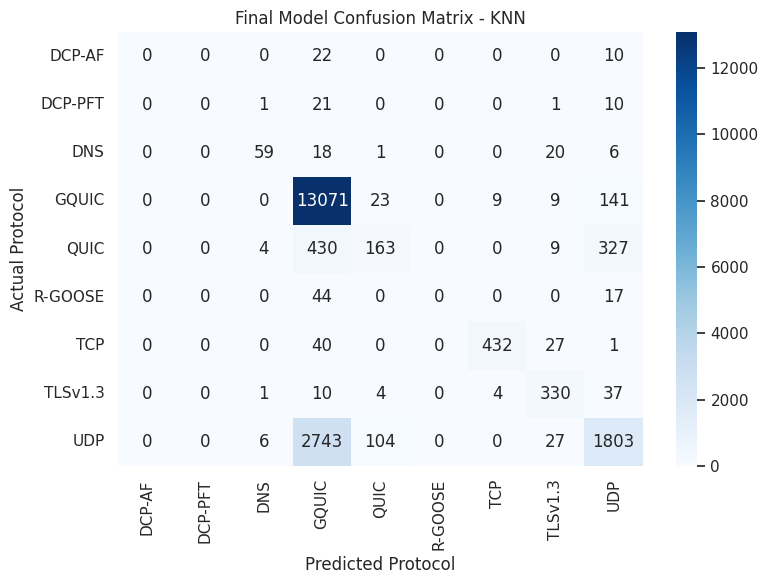

In [29]:
clean_results = results[results["Feature set"] == clean_set].sort_values("Macro F1 (%)", ascending=False)
display(clean_results.round(2))

best_name  = clean_results.iloc[0]["Model"]
best_model = experiments[clean_set][best_name]["model"]
best_pred  = experiments[clean_set][best_name]["pred"]

print("FINAL MODEL:", best_name)
print(f"Accuracy          : {accuracy_score(y_test, best_pred)*100:.2f}%")
print(f"Balanced Accuracy : {balanced_accuracy_score(y_test, best_pred)*100:.2f}%")
print(f"Macro F1          : {f1_score(y_test, best_pred, average='macro', zero_division=0)*100:.2f}%")
print()
print(classification_report(y_test, best_pred, labels=labels_all,
                            target_names=class_names, zero_division=0))

cm = confusion_matrix(y_test, best_pred, labels=labels_all)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted Protocol"); plt.ylabel("Actual Protocol")
plt.title(f"Final Model Confusion Matrix - {best_name}")
plt.tight_layout(); plt.show()

In [30]:
new_packet = pd.DataFrame({"Length": [64]})
print("New packet:")
display(new_packet)

pred_code = best_model.predict(new_packet)
print("Predicted Protocol:", label_encoder.inverse_transform(pred_code)[0])

New packet:


,Length
0,64


Predicted Protocol: UDP


FINAL RANDOM FOREST EVALUATION
Feature Set: Length + Time (time shortcut)
Accuracy          : 95.93%
Balanced Accuracy : 61.95%
Precision (Macro) : 62.54%
Recall (Macro)    : 61.95%
F1 Score (Macro)  : 61.92%

DETAILED CLASSIFICATION REPORT
              precision    recall  f1-score   support

      DCP-AF       0.01      0.03      0.02        32
     DCP-PFT       0.02      0.06      0.03        33
         DNS       0.79      0.74      0.76       104
       GQUIC       1.00      1.00      1.00     13253
        QUIC       0.92      0.87      0.89       933
     R-GOOSE       0.01      0.05      0.02        61
         TCP       0.98      0.99      0.99       500
     TLSv1.3       0.96      0.95      0.95       386
         UDP       0.94      0.89      0.92      4683

    accuracy                           0.96     19985
   macro avg       0.63      0.62      0.62     19985
weighted avg       0.97      0.96      0.97     19985



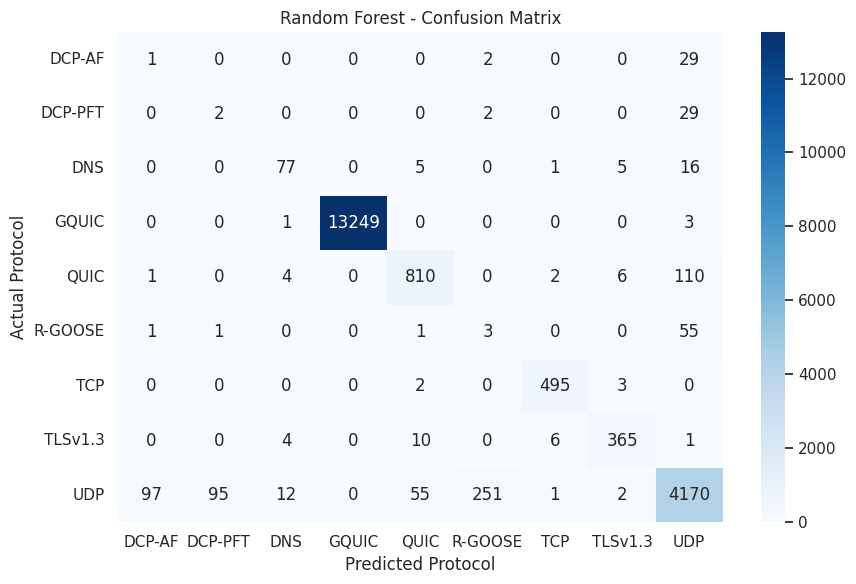

In [31]:

# FINAL RANDOM FOREST EVALUATION
# Using your existing model and predictions from Cell 18

rf_pred = experiments[time_set]["Random Forest"]["pred"]

print("=" * 55)
print("FINAL RANDOM FOREST EVALUATION")
print("Feature Set:", time_set)
print("=" * 55)

print(f"Accuracy          : {accuracy_score(y_test, rf_pred) * 100:.2f}%")
print(f"Balanced Accuracy : {balanced_accuracy_score(y_test, rf_pred) * 100:.2f}%")
print(f"Precision (Macro) : {precision_score(y_test, rf_pred, average='macro', zero_division=0) * 100:.2f}%")
print(f"Recall (Macro)    : {recall_score(y_test, rf_pred, average='macro', zero_division=0) * 100:.2f}%")
print(f"F1 Score (Macro)  : {f1_score(y_test, rf_pred, average='macro', zero_division=0) * 100:.2f}%")

print("\nDETAILED CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    rf_pred,
    labels=labels_all,
    target_names=class_names,
    zero_division=0
))

# Confusion Matrix
cm = confusion_matrix(y_test, rf_pred, labels=labels_all)

plt.figure(figsize=(9, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Protocol")
plt.ylabel("Actual Protocol")
plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()


                 MODEL COMPARISON
          NETWORK PROTOCOL CLASSIFICATION


,Model,Accuracy (%),Balanced Accuracy (%),Macro F1 (%)
1,KNN,79.35,42.58,45.16
3,Random Forest,74.58,47.89,39.89
2,Decision Tree,70.88,47.57,36.13
0,Logistic Regression,62.28,26.41,16.19


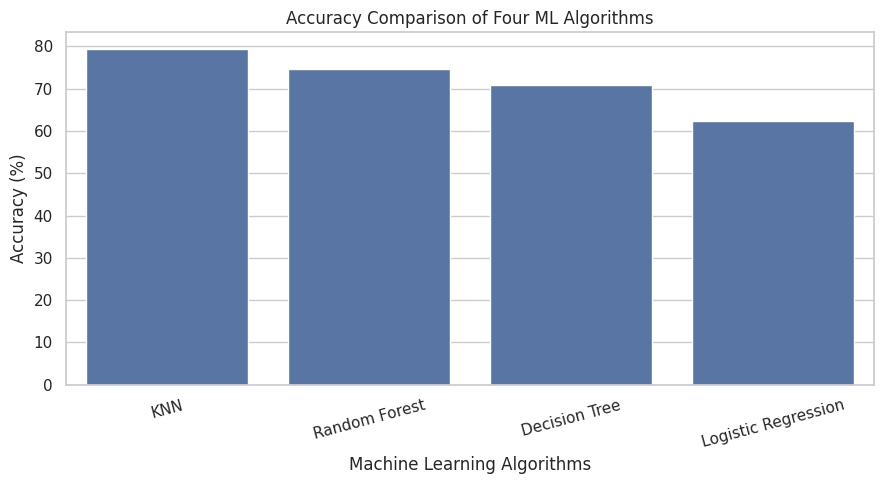


                 BEST MODEL
Model: KNN
Accuracy: 79.35%
Balanced Accuracy: 42.58%
Macro F1-Score: 45.16%


In [32]:

# ================================================================
#       MODEL COMPARISON - NETWORK PROTOCOL CLASSIFICATION
# ================================================================

# Compare all four models using the clean feature set
comparison = results[
    results["Feature set"] == clean_set
].sort_values("Accuracy (%)", ascending=False)

print("=" * 65)
print("                 MODEL COMPARISON")
print("          NETWORK PROTOCOL CLASSIFICATION")
print("=" * 65)

display(comparison[
    ["Model", "Accuracy (%)", "Balanced Accuracy (%)", "Macro F1 (%)"]
].round(2))

# Accuracy comparison graph
plt.figure(figsize=(9, 5))

sns.barplot(
    data=comparison,
    x="Model",
    y="Accuracy (%)"
)

plt.title("Accuracy Comparison of Four ML Algorithms")
plt.xlabel("Machine Learning Algorithms")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Best model based on accuracy
best_accuracy_model = comparison.iloc[0]

print("\n" + "=" * 65)
print("                 BEST MODEL")
print("=" * 65)

print("Model:", best_accuracy_model["Model"])
print(f"Accuracy: {best_accuracy_model['Accuracy (%)']:.2f}%")
print(f"Balanced Accuracy: {best_accuracy_model['Balanced Accuracy (%)']:.2f}%")
print(f"Macro F1-Score: {best_accuracy_model['Macro F1 (%)']:.2f}%")

print("=" * 65)


In [33]:
new_packet = pd.DataFrame({"Length": [64]})
print("New packet:")
display(new_packet)

pred_code = best_model.predict(new_packet)
print("Predicted Protocol:", label_encoder.inverse_transform(pred_code)[0])

New packet:


,Length
0,64


Predicted Protocol: UDP


          NETWORK PROTOCOL CLASSIFICATION USING ML

                     PROJECT OVERVIEW

  Project: Network Protocol Classification Using Machine Learning

  Objective:
  To classify network packets into different protocol
  categories using machine learning algorithms.

  Algorithms Implemented:
  1. Logistic Regression
  2. K-Nearest Neighbors (KNN)
  3. Decision Tree
  4. Random Forest

                  MODEL PERFORMANCE COMPARISON


,Model,Accuracy (%),Balanced Accuracy (%),Macro F1 (%)
0,KNN,79.35,42.58,45.16
1,Random Forest,74.58,47.89,39.89
2,Decision Tree,70.88,47.57,36.13
3,Logistic Regression,62.28,26.41,16.19


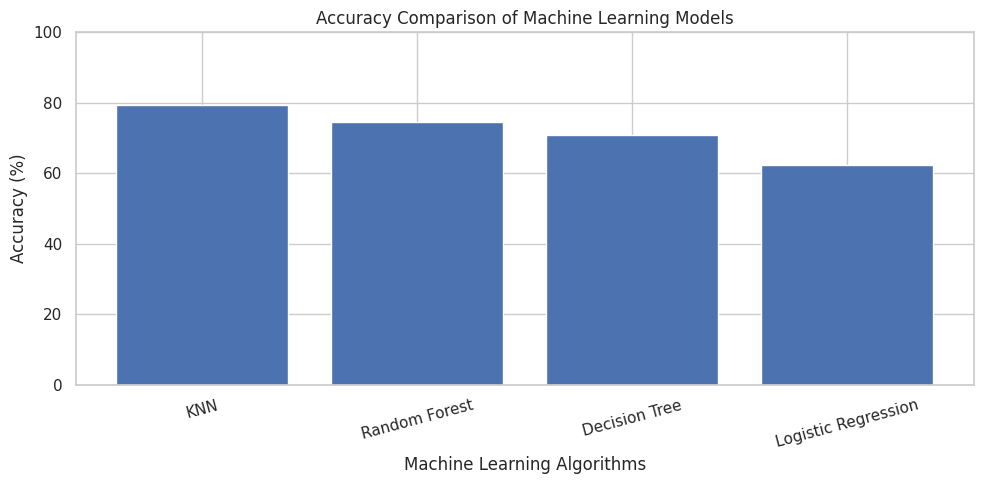


                     BEST MODEL

  Best Model: K-Nearest Neighbors (KNN)

  Accuracy             : 79.35%
  Balanced Accuracy    : 42.58%
  Macro F1-Score       : 45.16%

  KNN achieved the highest overall accuracy and Macro F1-score.
  Random Forest achieved the highest balanced accuracy (47.89%).

                   PROJECT CONCLUSION

  The Network Protocol Classification project successfully
  implemented and compared four machine learning algorithms.

  KNN achieved the highest accuracy of 79.35%, making it the
  best model based on overall accuracy.

  Random Forest achieved the highest balanced accuracy
  of 47.89%.

  The results indicate that classification performance
  varies across different network protocol classes.

  Future improvements can focus on handling class imbalance,
  adding useful network traffic features, and improving
  minority-class classification performance.

              PROJECT EVALUATION COMPLETED
          NETWORK PROTOCOL CLASSIFICATION
           

In [34]:

# ================================================================
#             FINAL PROJECT DASHBOARD
#       NETWORK PROTOCOL CLASSIFICATION USING ML
# ================================================================

import pandas as pd
import matplotlib.pyplot as plt

# Model comparison results
dashboard_results = pd.DataFrame({
    "Model": [
        "KNN",
        "Random Forest",
        "Decision Tree",
        "Logistic Regression"
    ],
    "Accuracy (%)": [79.35, 74.58, 70.88, 62.28],
    "Balanced Accuracy (%)": [42.58, 47.89, 47.57, 26.41],
    "Macro F1 (%)": [45.16, 39.89, 36.13, 16.19]
})

print("=" * 70)
print("          NETWORK PROTOCOL CLASSIFICATION USING ML")
print("=" * 70)

print("\n" + "=" * 70)
print("                     PROJECT OVERVIEW")
print("=" * 70)

print("""
  Project: Network Protocol Classification Using Machine Learning

  Objective:
  To classify network packets into different protocol
  categories using machine learning algorithms.

  Algorithms Implemented:
  1. Logistic Regression
  2. K-Nearest Neighbors (KNN)
  3. Decision Tree
  4. Random Forest
""")

print("=" * 70)
print("                  MODEL PERFORMANCE COMPARISON")
print("=" * 70)

display(dashboard_results)

# Accuracy comparison chart
plt.figure(figsize=(10, 5))
plt.bar(
    dashboard_results["Model"],
    dashboard_results["Accuracy (%)"]
)
plt.title("Accuracy Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Algorithms")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

print("\n" + "=" * 70)
print("                     BEST MODEL")
print("=" * 70)

print("""
  Best Model: K-Nearest Neighbors (KNN)

  Accuracy             : 79.35%
  Balanced Accuracy    : 42.58%
  Macro F1-Score       : 45.16%

  KNN achieved the highest overall accuracy and Macro F1-score.
  Random Forest achieved the highest balanced accuracy (47.89%).
""")

print("=" * 70)
print("                   PROJECT CONCLUSION")
print("=" * 70)

print("""
  The Network Protocol Classification project successfully
  implemented and compared four machine learning algorithms.

  KNN achieved the highest accuracy of 79.35%, making it the
  best model based on overall accuracy.

  Random Forest achieved the highest balanced accuracy
  of 47.89%.

  The results indicate that classification performance
  varies across different network protocol classes.

  Future improvements can focus on handling class imbalance,
  adding useful network traffic features, and improving
  minority-class classification performance.
""")

print("=" * 70)
print("              PROJECT EVALUATION COMPLETED")
print("          NETWORK PROTOCOL CLASSIFICATION")
print("                 FINAL DASHBOARD")
print("=" * 70)
